# VALORA AI: Research extension (exploratory)

**Status:** exploratory research done **after** the final Capstone was completed and validated. It does **not** change the final project. It uses only the 1,098 **development** listings and the **existing** 5 group-aware folds. The 278 test listings are never loaded into a model.

**Questions:**
1. Can machine learning improve on the simple city €/m² rule?
2. Can better property features and alternative target transformations improve prediction?

The plan, including the decision rules, was fixed before running: see `EXPERIMENT_PLAN.md`.

## 1. Summary

- **Integrity:** the three reference methods reproduce the final project's stored fold MAEs **exactly**, with the same 1,098 development listings and the same folds. No test listing was used.
- **Nothing beats the city €/m² rule (R0, CV MAE €50,527) under the final project's selection rule.** 15 configurations were run. Only one new idea gives a gain larger than its uncertainty:
  - **F1, location within the city:** neighbourhood or settlement on top of the city.
  - F1 lowers CV MAE to **€49,502**, a paired gain of €1,025 against the rule (SE €864) and €2,229 against its own control (SE €441).
  - The gain is concentrated in **Podgorica** (MAE €30,784 → €24,246, n = 389). It does **not** reduce large errors.
  - It is a weak, exploratory signal. Under the pre-registered 1-SE simplicity rule, the rule still wins.
- **No value found for:**
  - **€/m² targets** (A1–A3). Log €/m² is mathematically almost the same as the existing log-price model.
  - **Hybrid corrections** (B1–B4). Nested tuning chose the strongest shrinkage, i.e. "almost don't correct".
  - **Learned room counts** (D2–D3). Rooms are estimable from area, but they add no price information.
  - **City-specific area effects** (E1).
- **Correction to the final project's narrative:** on the 278 test listings the tree models had clearly better RMSE and R² than the rule. In cross-validation on the 1,098 development listings they do **not** (Random Forest pooled R² 0.563 vs 0.582 for the rule). That test-set observation does not replicate and should not be presented as a robust finding.

## 2. Setup, data and folds

**What this code does:** Loads the frozen processed dataset and fold assignment from the final project (read-only), checks that no test listing is included, and checks that the folds are exactly the final project's folds.

**Why we need it:** Every comparison must use the same population and the same folds as the final project. Otherwise differences could come from the data rather than the method.

In [1]:
import sys, json, hashlib, time
from pathlib import Path
sys.dont_write_bytecode = True
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mticker
from IPython.display import display
HERE = Path.cwd() if (Path.cwd() / 'lib').is_dir() else Path.cwd().parent
FINAL = HERE.parent / 'valora_ai'
sys.path.insert(0, str(HERE / 'lib'))
import valora_prep as vp, valora_model as vm, valora_plot as vplot, rx
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
vplot.apply_style(); pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)
RES, FIG = HERE / 'results', HERE / 'figures'
RES.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

data = pd.read_csv(FINAL / 'data' / 'processed' / 'valora_apartments_clean.csv')
folds_df = pd.read_csv(FINAL / 'docs' / 'results' / 'cv_folds.csv')
split = pd.read_csv(FINAL / 'docs' / 'results' / 'split_assignment.csv')
dev = folds_df[['record_id', 'cv_fold']].merge(data, on='record_id', how='left')       # same row order as the final notebook
test_ids = set(split.loc[split['split'] == 'test', 'record_id'])
assert len(dev) == 1098 and not set(dev['record_id']) & test_ids and dev['population'].eq('primary').all()
fingerprint = hashlib.sha256(json.dumps([dev.loc[dev['cv_fold'] == k, 'record_id'].tolist() for k in range(5)]).encode()).hexdigest()[:12]
assert fingerprint == 'dd9f21b7d8b6', fingerprint
FOLDS = dev['cv_fold']
y = dev['price_eur'].to_numpy(float)
print(f'Development listings: {len(dev)} | test listings loaded into models: 0 | fold fingerprint {fingerprint} (matches final project)')

Development listings: 1098 | test listings loaded into models: 0 | fold fingerprint dd9f21b7d8b6 (matches final project)


## 3. Reference methods: reproduce the final project exactly

**What this code does:** Re-runs the three reference methods (R0 city rule, R1 log-target Ridge, R2 Random Forest) and compares their fold-by-fold MAE with the values stored by the final project.

**Why we need it:** If this code reproduces the stored numbers exactly, the new experiments use the same data, folds and pipelines, and any difference really comes from the new method.

In [2]:
RF = dict(n_estimators=300, min_samples_leaf=2, random_state=42, n_jobs=2)
rows, OOF, MAES = [], {}, {}
def run(name, factory, inputs, complexity, notes='', control='R0'):
    row, oof, maes = rx.evaluate(name, factory, dev, FOLDS, inputs, MAES.get(control), complexity, notes)
    rows.append(row); OOF[name] = oof; MAES[name] = maes
    print(f"{name:4} CV MAE €{row['cv_mae_mean']:,.0f} ± {row['cv_mae_std']:,.0f}" +
          (f" | paired vs R0 {row['paired_diff_vs_R0_mean']:+,.0f} (SE {row['paired_diff_vs_R0_se']:,.0f})" if 'paired_diff_vs_R0_mean' in row else '') +
          f" | {row['fit_time_s']:.1f}s")
    return row

run('R0', lambda: vm.CityPricePerM2Baseline('city_clean'), ['area_m2', 'city_clean'], 1, 'City median €/m² × area (final model)')
run('R1', lambda: vm.make_model_pipeline('D: clean city + engineered', Ridge(alpha=1.0), scale=True, log_target=True), rx.BASE_INPUTS, 2, 'Ridge, log target, set D')
run('R2', lambda: vm.make_model_pipeline('C2: + clean city', RandomForestRegressor(**RF)), rx.BASE_INPUTS, 3, 'Random Forest, C2')
stored = pd.read_csv(FINAL / 'docs' / 'results' / 'cv_results.csv').set_index('model')
for rid, name in [('R0', 'City €/m² × area baseline'), ('R1', 'Ridge, log target (engineered)'), ('R2', 'Random Forest')]:
    ok = np.allclose(MAES[rid], stored.loc[name, [f'fold_{k}' for k in range(5)]].to_numpy(float), rtol=1e-9)
    print(f'{rid} reproduces stored fold MAEs of "{name}": {ok}'); assert ok

R0   CV MAE €50,527 ± 6,297 | 0.1s


R1   CV MAE €51,595 ± 5,153 | paired vs R0 +1,068 (SE 627) | 0.2s


R2   CV MAE €56,061 ± 3,753 | paired vs R0 +5,534 (SE 1,268) | 3.2s
R0 reproduces stored fold MAEs of "City €/m² × area baseline": True
R1 reproduces stored fold MAEs of "Ridge, log target (engineered)": True
R2 reproduces stored fold MAEs of "Random Forest": True


## 4. Experiment A: modelling price per m²

The model learns the asking price **per m²** and multiplies its prediction by the area. All metrics are still computed on the **total price in euros**. The true €/m² is only the *target*, never an input.

**How A2 relates to R1:** log(price) = log(€/m²) + log(area). R1 already has log(area) as an input. A Ridge model on log(€/m²) is therefore the **same linear model** as R1, except that the log(area) coefficient is shifted by exactly 1, and the penalty acts on the shifted coefficient. A2 should give almost the same result as R1. It is a check of the mathematics, not a new discovery.

**What this code does:** Runs A1 (Ridge on €/m²), A2 (Ridge on log €/m²) and A3 (Random Forest on €/m²) with the same folds.

**Why we need it:** To test whether €/m², the quantity valuers think in, is a better modelling target.

In [3]:
run('A1', lambda: rx.PricePerM2Regressor(vm.make_model_pipeline('D: clean city + engineered', Ridge(alpha=1.0), scale=True)), rx.BASE_INPUTS, 2, 'Ridge on €/m², set D')
run('A2', lambda: rx.PricePerM2Regressor(vm.make_model_pipeline('D: clean city + engineered', Ridge(alpha=1.0), scale=True), log=True), rx.BASE_INPUTS, 2, 'Ridge on log €/m², set D')
run('A3', lambda: rx.PricePerM2Regressor(vm.make_model_pipeline('C2: + clean city', RandomForestRegressor(**RF))), rx.BASE_INPUTS, 3, 'Random Forest on €/m², C2')
d, se, sig = rx.paired(MAES['A2'], MAES['R1'])
print(f'A2 vs R1 paired MAE difference: {d:+,.0f} (SE {se:,.0f}); max abs fold difference €{np.max(np.abs(MAES["A2"] - MAES["R1"])):,.0f}')

A1   CV MAE €53,406 ± 4,870 | paired vs R0 +2,879 (SE 719) | 0.1s


A2   CV MAE €51,551 ± 5,215 | paired vs R0 +1,024 (SE 598) | 0.1s


A3   CV MAE €54,900 ± 4,514 | paired vs R0 +4,373 (SE 1,511) | 2.5s
A2 vs R1 paired MAE difference: -44 (SE 41); max abs fold difference €206


**What it means:**

| Config | CV MAE | Paired vs R0 (SE) |
|---|---|---|
| A1 Ridge on €/m² | €53,406 ± 4,870 | +€2,879 (719) |
| A2 Ridge on log €/m² | €51,551 ± 5,215 | +€1,024 (598) |
| A3 Random Forest on €/m² | €54,900 ± 4,514 | +€4,373 (1,511) |

- **A2 equals R1, as the mathematics predicts.** The paired difference is −€44 (SE €41), and no fold differs by more than €206. This is the same model written differently, not a new finding.
- **A1** (plain €/m², not log) is worse.
- **A3:** a Random Forest on €/m² is about €1,160 better than the same forest on total price (R2; SE €936). It is still €4,373 worse than the rule.
- **Answer:** predicting €/m² does **not** beat predicting the total price in a way that matters. It mainly helps the tree model, which remains clearly behind the rule.

## 5. Experiment B: hybrid rule + learned correction

The city €/m² rule gives the starting estimate, and a model learns how much to **correct** it.
- **B1 additive:** correction in euros.
- **B2 multiplicative:** correction factor.
- **B3 log:** log correction, i.e. a percentage.
- **B4:** the B3 correction learned by Gradient Boosting instead of Ridge.

**Leakage protection:**
- The corrections are learned on **out-of-fold baselines**. Each training listing's city median is computed from inner group-aware folds that exclude its own repeat group, so a listing's own price never shapes its starting estimate.
- The Ridge penalty α is chosen by an inner group-aware CV inside each outer training fold (nested).
- A very large α shrinks the correction towards a constant level adjustment. The intercept is not penalised, so it does not shrink exactly to zero.

**What this code does:** Runs B1–B4 with the same outer folds. Each outer training fold gets its own out-of-fold baselines and its own nested choice of α.

**Why we need it:** This is the main experiment: can ML improve the rule rather than replace it?

In [4]:
HYB = rx.BASE_INPUTS + ['repeat_group']
ridge_corr = lambda: vm.make_model_pipeline('D: clean city + engineered', Ridge(), scale=True)
HGB = dict(learning_rate=0.05, max_iter=200, max_leaf_nodes=8, min_samples_leaf=40, l2_regularization=5.0, random_state=42)
run('B1', lambda: rx.HybridRegressor(ridge_corr(), 'additive'), HYB, 2, 'Rule + additive Ridge correction (nested α)')
run('B2', lambda: rx.HybridRegressor(ridge_corr(), 'multiplicative'), HYB, 2, 'Rule × multiplicative Ridge correction (nested α)')
run('B3', lambda: rx.HybridRegressor(ridge_corr(), 'log'), HYB, 2, 'Rule × exp(log Ridge correction) (nested α)')
run('B4', lambda: rx.HybridRegressor(vm.make_model_pipeline('D: clean city + engineered', HistGradientBoostingRegressor(**HGB)), 'log', tune_alpha=False), HYB, 3, 'Rule × exp(log HGB correction), fixed settings')

B1   CV MAE €51,937 ± 6,326 | paired vs R0 +1,410 (SE 220) | 2.4s


B2   CV MAE €51,818 ± 6,572 | paired vs R0 +1,291 (SE 357) | 2.4s


B3   CV MAE €50,731 ± 5,768 | paired vs R0 +204 (SE 287) | 2.5s


B4   CV MAE €52,128 ± 5,864 | paired vs R0 +1,601 (SE 859) | 1.0s


{'id': 'B4',
 'cv_mae_mean': np.float64(52128.070919683654),
 'cv_mae_std': np.float64(5863.911864544645),
 'cv_rmse_mean': np.float64(102525.84477981812),
 'cv_r2_mean': np.float64(0.5747626076628218),
 'oof_rmse_pooled': 104967.43015817317,
 'oof_r2_pooled': 0.5684231015047436,
 'oof_median_ae': 27458.73142057995,
 'fit_time_s': 0.9555272000143304,
 'complexity': 3,
 'notes': 'Rule × exp(log HGB correction), fixed settings',
 'fold_0': np.float64(56486.2787585847),
 'fold_1': np.float64(46082.97916306262),
 'fold_2': np.float64(45448.56421734307),
 'fold_3': np.float64(55217.94932294989),
 'fold_4': np.float64(57404.58313647798),
 'paired_diff_vs_R0_mean': np.float64(1601.1938967883107),
 'paired_diff_vs_R0_se': np.float64(859.0991247885679),
 'signal_vs_R0': False}

**What this code does:** Checks the leakage protection directly. For one outer training fold, it confirms that each listing's out-of-fold baseline equals a city rule fitted **without** that listing's repeat group.

**Why we need it:** To show, not just state, that a listing's own price (and the prices of its probable duplicates) never enters its starting estimate.

In [5]:
tr = dev[FOLDS != 0].reset_index(drop=True)
h = rx.HybridRegressor(ridge_corr(), 'log', tune_alpha=False).fit(tr[HYB], tr['price_eur'].to_numpy(float))
rng = np.random.default_rng(0); checked = 0
from sklearn.model_selection import GroupKFold
inner = list(GroupKFold(5, shuffle=True, random_state=42).split(tr, groups=tr['repeat_group']))
for i in rng.choice(len(tr), 25, replace=False):
    fit_rows = next(t for t, v in inner if i in v)
    assert tr.loc[i, 'repeat_group'] not in set(tr.loc[fit_rows, 'repeat_group'])
    b = vm.CityPricePerM2Baseline('city_clean').fit(tr.loc[fit_rows], tr.loc[fit_rows, 'price_eur'].to_numpy(float))
    assert np.isclose(b.predict(tr.loc[[i]])[0], h.base_oof_[i]); checked += 1
print(f'{checked}/25 sampled training listings: out-of-fold baseline excludes the listing and its repeat group - OK')

25/25 sampled training listings: out-of-fold baseline excludes the listing and its repeat group - OK


**What it means:**

| Config | CV MAE | Paired vs R0 (SE) | Pooled out-of-fold R² | Chosen α per fold |
|---|---|---|---|---|
| R0 rule | €50,527 ± 6,297 | – | 0.582 | – |
| B1 additive | €51,937 ± 6,326 | +€1,410 (220) | 0.590 | 10,000 in all 5 |
| B2 multiplicative | €51,818 ± 6,572 | +€1,291 (357) | 0.591 | 10,000 in all 5 |
| B3 log | €50,731 ± 5,768 | +€204 (287) | 0.579 | 1,000 in all 5 |
| B4 log, Gradient Boosting | €52,128 ± 5,864 | +€1,601 (859) | 0.568 | fixed |

- **No hybrid beats the rule on MAE.** B3 is practically equal (+€204 ± 287). B1 and B2 are slightly but consistently worse on MAE: their paired gap is larger than its SE.
- **The tuning itself is informative.** Inside every outer fold, the inner group CV chose the **largest** penalty offered for B1 and B2 (α = 10,000, the edge of the grid) and a large one for B3. The data prefer a correction close to a constant level shift. In other words: *the learned corrections do not generalise well enough to beat the rule*. The grid was **not** extended after seeing this.
- **B1 and B2 have slightly lower RMSE** (pooled €102.1–102.4k vs €103.3k) and higher R² (0.59 vs 0.58). They trade slightly worse typical errors for slightly smaller large errors. The difference is about 1%.
- **The rule's main weakness is not fixed.** For flats ≥ €500k the mean error is −€296k for R0 and −€308k for B3 (Section 11).
- **Leakage check passed:** for 25 sampled training listings, the out-of-fold baseline was recomputed by hand from a rule fitted without the listing's repeat group, and it matched.

## 6. Experiment D: rooms and missing room counts

### 6.1 Audit (development data)

**What this code does:** Counts known and missing room counts by platform and city. It compares the area of listings with and without a room count, and shows the area range for each room count.

**Why we need it:** Before imputing anything, we need to know how many values are missing, where, and whether they are missing at random.

In [6]:
miss = dev['rooms'].isna()
print('Rooms known:', int((~miss).sum()), '| missing:', int(miss.sum()), f'({miss.mean():.1%}) | studios (0 rooms):', int((dev['rooms'] == 0).sum()))
display(pd.crosstab(dev['platform'], miss.map({False: 'known', True: 'missing'}), margins=True))
display(dev.groupby('city_clean').agg(n=('rooms', 'size'), missing_pct=('rooms', lambda s: round(100 * s.isna().mean()))).query('n >= 20').sort_values('missing_pct', ascending=False))
display(dev.groupby(miss.map({False: 'rooms known', True: 'rooms missing'}))[['area_m2', 'price_eur']].median().round(0))
display(dev.groupby('rooms')['area_m2'].describe(percentiles=[.1, .5, .9]).round(0)[['count', '10%', '50%', '90%']])

Rooms known: 935 | missing: 163 (14.8%) | studios (0 rooms): 21


rooms,known,missing,All
platform,,,
Estitor,324,2,326
Realitica,587,161,748
Realitica Adriatic,24,0,24
All,935,163,1098


,n,missing_pct
city_clean,,
Bar,62,73
Kolašin,41,63
Ulcinj,45,22
Cetinje,27,15
Budva,184,14
Kotor,46,13
Herceg Novi,180,7
Tivat,62,6
Podgorica,389,6


,area_m2,price_eur
rooms,,
rooms known,63.0,182000.0
rooms missing,51.0,145000.0


,count,10%,50%,90%
rooms,,,,
0.0,21.0,24.0,30.0,35.0
1.0,421.0,36.0,47.0,61.0
2.0,356.0,58.0,70.0,100.0
3.0,128.0,74.0,101.0,168.0
4.0,7.0,89.0,106.0,159.0
5.0,1.0,230.0,230.0,230.0
6.0,1.0,334.0,334.0,334.0


**What it means:**
- **Missing:** 163 of 1,098 development listings (14.8%) have no room count. **161 of them are Realitica** adverts whose title gives no rooms. Estitor and Adriatic are almost complete.
- **Studios:** the 21 studios are stored as 0 rooms (from *garsonjera*). Zero means studio, never "missing".
- **Not missing at random:**
  - missingness depends strongly on the city (Bar 73%, Kolašin 63%, Podgorica 6%, Herceg Novi 7%);
  - listings without rooms are smaller and cheaper (median 51 m² / €145k vs 63 m² / €182k).
- **What "rooms" means:** the data contain the advertised **room** count (*jednosoban* = one-bedroom flat). We cannot separate bedrooms from other rooms, so the variable is "rooms as advertised", not a verified bedroom count.
- **Rooms and area:** rooms follow area closely, but the ranges overlap (10th–90th percentile: 1 room 36–61 m²; 2 rooms 58–100 m²; 3 rooms 74–168 m²). Any area-based estimate will therefore be uncertain near the boundaries.
- No area thresholds were assumed: D2 uses training-quintile bins, and D3 learns the relationship.

### 6.2 How well can rooms be estimated? (masking validation)

**What this code does:** For each fold: fits the three room estimators on the **training** fold's known values, estimates the known room counts of the validation fold as if they were missing, and compares with the truth. It also computes a version reweighted to the real missingness pattern (by city).

**Why we need it:** If rooms cannot be estimated well from area and city, imputing them cannot add much information. A good result on masked known values does **not** prove the same accuracy on the truly missing ones.

In [7]:
val_rows = []
for k in range(5):
    tr, va = dev[FOLDS != k], dev[(FOLDS == k) & dev['rooms'].notna()]
    w_city = tr.groupby('city_clean')['rooms'].apply(lambda s: s.isna().mean())
    for method in ['median', 'area_bin', 'learned']:
        est = rx.RoomsImputer(method).fit(tr).estimate(va)
        val_rows.append(pd.DataFrame({'method': method, 'fold': k, 'true': va['rooms'].to_numpy(), 'est': est,
                                      'area_m2': va['area_m2'].to_numpy(), 'city': va['city_clean'].to_numpy(),
                                      'platform': va['platform'].to_numpy(), 'weight': va['city_clean'].map(w_city).fillna(0).to_numpy()}))
mv = pd.concat(val_rows, ignore_index=True)
mv['abs_err'] = (mv['est'] - mv['true']).abs(); mv['exact'] = mv['est'].round() == mv['true']
summary = pd.DataFrame({m: {'n': len(g), 'exact_match_%': 100 * g['exact'].mean(), 'MAE_rooms': g['abs_err'].mean(),
                             'MAE_rooms_weighted_to_missing_pattern': np.average(g['abs_err'], weights=g['weight'])}
                        for m, g in mv.groupby('method')}).T.round(3)
display(summary); summary.to_csv(RES / 'rooms_masking_validation.csv')
mv['area_band'] = pd.cut(mv['area_m2'], [0, 40, 60, 80, 120, np.inf], labels=['<40', '40–60', '60–80', '80–120', '≥120'])
display(mv.pivot_table(index='area_band', columns='method', values='abs_err', aggfunc='mean', observed=True).round(2).assign(n=mv[mv.method == 'learned'].groupby('area_band', observed=True).size()))
display(mv.pivot_table(index='platform', columns='method', values='abs_err', aggfunc='mean').round(2).assign(n=mv[mv.method == 'learned'].groupby('platform').size()))
display(mv[mv.method == 'learned'].groupby('city').agg(n=('abs_err', 'size'), MAE_rooms=('abs_err', 'mean')).query('n >= 20').round(2))

,n,exact_match_%,MAE_rooms,MAE_rooms_weighted_to_missing_pattern
area_bin,935.0,71.444,0.296,0.273
learned,935.0,76.898,0.317,0.305
median,935.0,38.075,0.655,0.675


method,area_bin,learned,median,n
area_band,,,,
<40,0.20,0.18,1.16,105
40–60,0.25,0.25,0.86,340
60–80,0.24,0.33,0.24,263
80–120,0.50,0.47,0.52,171
≥120,0.43,0.48,0.82,56


method,area_bin,learned,median,n
platform,,,,
Estitor,0.23,0.28,0.72,324
Realitica,0.32,0.33,0.62,587
Realitica Adriatic,0.50,0.38,0.58,24


,n,MAE_rooms
city,,
Budva,158,0.34
Cetinje,23,0.18
Herceg Novi,167,0.39
Kotor,40,0.37
Nikšić,23,0.39
Podgorica,364,0.29
Tivat,58,0.34
Ulcinj,35,0.19
Unknown,27,0.30


**What this code does:** Draws the rooms-estimation error by area band for the three methods.

**Why we need it:** To show where the area-based estimate is reliable and where it is not.

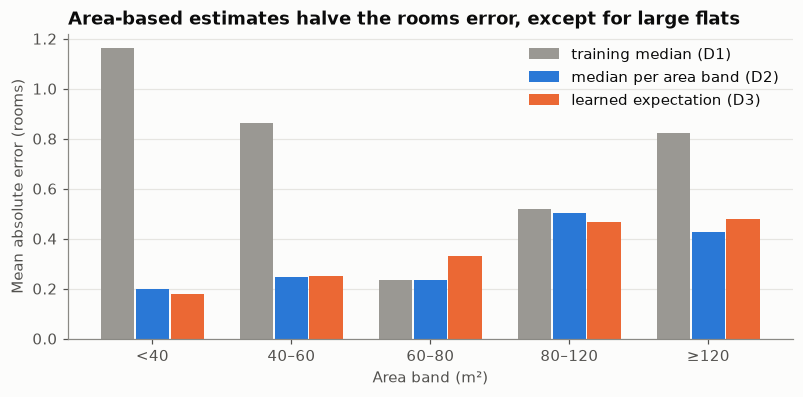

In [8]:
pv = mv.pivot_table(index='area_band', columns='method', values='abs_err', aggfunc='mean', observed=True)
fig, ax = plt.subplots(figsize=(8.5, 3.6)); x = np.arange(len(pv))
for off, (m, col) in zip([-0.25, 0, 0.25], [('median', vplot.GRAY), ('area_bin', vplot.BLUE), ('learned', vplot.ORANGE)]):
    ax.bar(x + off, pv[m], width=0.24, color=col, label={'median': 'training median (D1)', 'area_bin': 'median per area band (D2)', 'learned': 'learned expectation (D3)'}[m])
ax.set_xticks(x, pv.index.astype(str)); ax.set_xlabel('Area band (m²)'); ax.set_ylabel('Mean absolute error (rooms)')
ax.set_title('Area-based estimates halve the rooms error, except for large flats'); ax.legend(); ax.grid(axis='x', visible=False)
vplot.save(fig, FIG, 'rx_01_rooms_estimation_error'); plt.show()

### 6.3 Does better rooms handling improve the price estimate?

**What this code does:** Runs D1 (control: median imputation in the same pipeline family), D2 (area-band median) and D3 (learned expectation), all with a `rooms_missing` indicator and the same Ridge log-target model. It compares them on all listings and separately on the listings with missing rooms.

**Why we need it:** This is the main question about rooms: estimating rooms is only useful if it improves the **price** prediction.

In [9]:
run('D1', lambda: rx.ridge_log_pipeline('median'), rx.BASE_INPUTS, 2, 'Control: R1 family, median rooms before engineering')
run('D2', lambda: rx.ridge_log_pipeline('area_bin'), rx.BASE_INPUTS, 2, 'Rooms imputed by training area-quintile median')
run('D3', lambda: rx.ridge_log_pipeline('learned'), rx.BASE_INPUTS, 2, 'Rooms = expected value from P(rooms | log area, city)')
for v in ['D2', 'D3']:
    d, se, sig = rx.paired(MAES[v], MAES['D1']); print(f'{v} vs D1: paired MAE {d:+,.0f} (SE {se:,.0f}) signal={sig}')
sub = pd.DataFrame({m: {'rooms missing (n=%d)' % miss.sum(): np.mean(np.abs(OOF[m][miss] - y[miss])),
                        'rooms known (n=%d)' % (~miss).sum(): np.mean(np.abs(OOF[m][~miss] - y[~miss]))} for m in ['R0', 'R1', 'D1', 'D2', 'D3']}).round(0)
display(sub); sub.to_csv(RES / 'rooms_subset_mae.csv')

D1   CV MAE €51,731 ± 5,184 | paired vs R0 +1,204 (SE 647) | 0.1s
D2   CV MAE €51,720 ± 5,203 | paired vs R0 +1,193 (SE 624) | 0.1s


D3   CV MAE €51,736 ± 5,176 | paired vs R0 +1,209 (SE 627) | 0.3s
D2 vs D1: paired MAE -11 (SE 56) signal=False
D3 vs D1: paired MAE +4 (SE 45) signal=False


,R0,R1,D1,D2,D3
rooms missing (n=163),38451.0,35844.0,36401.0,35877.0,36015.0
rooms known (n=935),52612.0,54314.0,54372.0,54451.0,54446.0


**What it means:**

**Estimating rooms works reasonably** (masking validation on 935 known values, cross-fitted):

| Method | Exact match | Mean error (rooms) | Weighted to the real missing pattern |
|---|---|---|---|
| Training median (D1) | 38% | 0.66 | 0.68 |
| Median per area quintile (D2) | 71% | 0.30 | 0.27 |
| Learned expectation (D3) | 77%* | 0.32 | 0.31 |

\* D3 returns an expected value, which is rounded only for the exact-match check.

- Errors are smallest for small flats (≈ 0.2 rooms) and largest above 80 m² (≈ 0.45–0.5).

**But it does not improve the price estimate:**
- D2 vs D1: −€11 (SE €56). D3 vs D1: +€4 (SE €45).
- On the 163 listings with missing rooms, the MAE moves only from €36,401 (D1) to €35,877 (D2) and €36,015 (D3).

The reason: the estimated rooms are derived from area (and city), which the model already has. **They repeat existing information.**

**Recommendation:** keep the final project's simple handling (training median + `rooms_missing` indicator). Do not add an imputation model. Estimated room counts are never stored as real data.

## 7. Experiment E: different area effects per city

**What this code does:** Runs E1: the D1 model plus one extra slope of log(area) for every city with at least 30 training listings (the city one-hot is unchanged). It also shows the learned extra slopes, fitted on all development data, for interpretation.

**Why we need it:** In a resort town a large flat may be worth relatively more (or less) per m² than in Podgorica. If so, a single area effect for all cities is too simple.

In [10]:
run('E1', lambda: rx.ridge_log_pipeline('median', interaction=True), rx.BASE_INPUTS, 2, 'D1 + city × log(area) interactions (cities ≥ 30 training rows)')
d, se, sig = rx.paired(MAES['E1'], MAES['D1']); print(f'E1 vs D1: paired MAE {d:+,.0f} (SE {se:,.0f}) signal={sig}')
m = rx.ridge_log_pipeline('median', interaction=True).fit(dev[rx.BASE_INPUTS], y)
pipe = m.regressor_; names = pipe.named_steps['preprocess'].get_feature_names_out(); coef = pipe.named_steps['model'].coef_
sc = pipe.named_steps['preprocess'].named_transformers_['numeric'].named_steps['scale']
num_names = [n for n in names if n in list(pipe.named_steps['preprocess'].transformers_[0][2])]
inter = pd.Series({n: c / s for n, c, s in zip(num_names, coef[:len(num_names)], sc.scale_) if n.startswith('logA_x_')}).round(3)
display(inter.rename('extra log-area slope (descriptive, all dev data)').to_frame())

E1   CV MAE €51,897 ± 5,858 | paired vs R0 +1,370 (SE 646) | 0.2s


E1 vs D1: paired MAE +166 (SE 349) signal=False


,"extra log-area slope (descriptive, all dev data)"
logA_x_Bar,-0.227
logA_x_Budva,-0.034
logA_x_Herceg Novi,-0.112
logA_x_Kolašin,0.065
logA_x_Kotor,-0.069
logA_x_Podgorica,-0.105
logA_x_Tivat,-0.194
logA_x_Ulcinj,-0.200


**What it means:**
- **E1 does not help:** +€166 against D1 (SE €349).
- **The descriptive slopes** (relative to the common area slope) are negative for most coastal cities (Bar −0.23, Ulcinj −0.20, Tivat −0.19, Herceg Novi −0.11) and for Podgorica (−0.11). Roughly: price per m² falls more with size there.
- **These slopes are descriptive only.** With 41–389 listings per city, the extra parameters cost as much accuracy as they gain, so different area effects per city do **not** improve the model.
- **Area-per-room** has been part of the engineered feature set since the final project, where that set (log area, area², area per room, size group) did not improve Linear Regression or Random Forest. It was not re-tested separately here.

## 8. Experiment F: location within the city

### 8.1 Audit

**What this code does:** Counts how many listings have a usable location below city level (neighbourhood or settlement), how many such places have at least 10 listings, and whether the names are shared across platforms.

**Why we need it:** A neighbourhood is only useful if it is reliable, covered by enough listings, and not just a product of one platform's sampling.

In [11]:
loc = rx.add_city_neighbourhood(dev)
has_nb = ~loc['city_nb'].str.endswith('|-')
counts = loc.loc[has_nb, 'city_nb'].value_counts()
print(f'Listings with a sub-city location: {has_nb.sum()} of {len(dev)} | distinct places: {len(counts)} | places with ≥10 listings: {(counts >= 10).sum()} covering {counts[counts >= 10].sum()} listings')
display(pd.crosstab(loc['platform'], has_nb.map({True: 'has neighbourhood', False: 'city only'})))
display(counts[counts >= 10].rename('listings').to_frame())
pg = loc[loc['city_clean'] == 'Podgorica']
shared = set(pg.loc[pg.platform == 'Estitor', 'city_nb']) & set(pg.loc[pg.platform == 'Realitica', 'city_nb'])
print('Podgorica neighbourhood names on both platforms:', len(shared - {'Podgorica|-'}))

Listings with a sub-city location: 771 of 1098 | distinct places: 94 | places with ≥10 listings: 31 covering 569 listings


city_nb,city only,has neighbourhood
platform,,
Estitor,2,324
Realitica,323,425
Realitica Adriatic,2,22


,listings
city_nb,
Herceg Novi|djenovici,36
Podgorica|zabjelo,29
Herceg Novi|igalo,28
Budva|becici,24
Herceg Novi|topla,23
Podgorica|ljubovic,21
Podgorica|city kvart,21
Herceg Novi|kumbor,21
Herceg Novi|bijela,21


Podgorica neighbourhood names on both platforms: 17


**What it means:**
- 771 of 1,098 listings have a place below city level: a neighbourhood (e.g. Zabjelo) or a reviewed settlement (e.g. Igalo). 31 places have ≥ 10 listings, covering 569 listings.
- **Estitor (Podgorica) contributes 324** of these. Its neighbourhoods are capped at about 20 adverts each, so the neighbourhood mix reflects the scraping, not the market.
- 17 Podgorica neighbourhood names appear on **both** platforms, so the names are reasonably consistent.
- The location text names a real place, but it is the advertiser's description, not a verified address.
- No coordinates, sea distance or invented groupings were used.

**What this code does:** Runs F1: the D1 model plus a one-hot 'city|neighbourhood' feature. A place needs ≥ 10 **training** listings to get its own column; all others fall back to the city effect. It reports the MAE for all listings and for Podgorica, where most neighbourhood information is.

**Why we need it:** To measure whether finer location adds information beyond the city. One-hot encoding with regularisation needs no price statistics, so there is no target-encoding leakage.

In [12]:
NB_INPUTS = rx.BASE_INPUTS + ['neighbourhood']
run('F1', lambda: rx.ridge_log_pipeline('median', neighbourhood=True), NB_INPUTS, 2, 'D1 + one-hot city|neighbourhood (≥10 training rows, else city)')
d, se, sig = rx.paired(MAES['F1'], MAES['D1']); print(f'F1 vs D1: paired MAE {d:+,.0f} (SE {se:,.0f}) signal={sig}')
for name, mask in [('Podgorica', dev['city_clean'].eq('Podgorica')), ('with neighbourhood ≥10 listings', loc['city_nb'].isin(counts[counts >= 10].index)), ('other', ~loc['city_nb'].isin(counts[counts >= 10].index))]:
    print(f"{name:32} n={mask.sum():4} | MAE D1 €{np.mean(np.abs(OOF['D1'][mask] - y[mask])):,.0f} | F1 €{np.mean(np.abs(OOF['F1'][mask] - y[mask])):,.0f} | R0 €{np.mean(np.abs(OOF['R0'][mask] - y[mask])):,.0f}")

F1   CV MAE €49,502 ± 4,452 | paired vs R0 -1,025 (SE 864) | 0.2s


F1 vs D1: paired MAE -2,229 (SE 441) signal=True
Podgorica                        n= 389 | MAE D1 €30,784 | F1 €24,246 | R0 €30,992


with neighbourhood ≥10 listings  n= 569 | MAE D1 €38,161 | F1 €33,523 | R0 €37,536
other                            n= 529 | MAE D1 €66,271 | F1 €66,659 | R0 €64,465


**What it means:**

| | n | Control D1 | F1 (+ neighbourhood) | Rule R0 |
|---|---|---|---|---|
| All development | 1,098 | €51,731 | **€49,502** | €50,527 |
| Podgorica | 389 | €30,784 | **€24,246** | €30,992 |
| Places with ≥ 10 listings | 569 | €38,161 | €33,523 | €37,536 |
| All other listings | 529 | €66,271 | €66,659 | €64,465 |

- **Finer location is the only addition with a clear signal:**
  - against its control D1: −€2,229 (SE €441);
  - against the rule R0: −€1,025 (SE €864).
- **The gain is almost entirely in Podgorica,** where the neighbourhoods have enough listings (−21% MAE). Elsewhere nothing changes.
- **Typical errors improve, large errors do not.**
  - The median absolute error falls from €27,025 (R0) to €23,793.
  - The pooled RMSE is slightly higher (€104.9k vs €103.3k).
- **Caution:** much of the Podgorica neighbourhood information comes from **one platform with a capped sample**. This is a promising, exploratory finding that needs confirmation on new adverts.

## 9. Combination (only if the pre-registered conditions are met)

**What this code does:** Applies the combination rule fixed in `EXPERIMENT_PLAN.md`: take the best hybrid if it shows a signal against R0 (otherwise the R1 family), and add every feature change that showed a signal against D1. It runs that single combination, or reports why it was not run.

**Why we need it:** To check whether useful pieces add up, without trying every possible combination.

In [13]:
best_b = min(['B1', 'B2', 'B3', 'B4'], key=lambda b: MAES[b].mean())
hyb_signal = rx.paired(MAES[best_b], MAES['R0'])[2]
feat_signal = {v: rx.paired(MAES[v], MAES['D1'])[2] for v in ['D2', 'D3', 'E1', 'F1']}
rooms = None
if feat_signal['D2'] or feat_signal['D3']:
    rooms = {'D2': 'area_bin', 'D3': 'learned'}[min([v for v in ['D2', 'D3'] if feat_signal[v]], key=lambda v: MAES[v].mean())]
use_int, use_nb = feat_signal['E1'], feat_signal['F1']
print('best hybrid:', best_b, '| hybrid signal vs R0:', hyb_signal, '| feature signals vs D1:', feat_signal)
C1_RAN = hyb_signal or any(feat_signal.values())
if C1_RAN:
    inputs = NB_INPUTS if use_nb else rx.BASE_INPUTS
    kw = dict(rooms=rooms or 'median', interaction=use_int, neighbourhood=use_nb)
    if hyb_signal and best_b != 'B4':
        form = {'B1': 'additive', 'B2': 'multiplicative', 'B3': 'log'}[best_b]
        factory = lambda: rx.HybridRegressor(rx.ridge_log_pipeline(**kw, alpha=1.0, log_target=False), form, features=inputs)
        run('C1', factory, inputs + ['repeat_group'], 3, f'{best_b} + {kw}')
    elif hyb_signal and best_b == 'B4':
        run('C1', lambda: rx.HybridRegressor(rx.ridge_log_pipeline(**kw, regressor=HistGradientBoostingRegressor(**HGB), log_target=False), 'log', tune_alpha=False, features=inputs),
            inputs + ['repeat_group'], 3, f'B4 + {kw}')
    else:
        parts = [n for n, on in [('learned/area rooms', rooms is not None), ('city×area', use_int), ('neighbourhood', use_nb)] if on]
        run('C1', lambda: rx.ridge_log_pipeline(**kw), inputs, 3, 'Combination: D1 + ' + ' + '.join(parts) + (' (= F1)' if parts == ['neighbourhood'] else ''))
else:
    print('C1 not run: no experiment showed a signal (pre-registered rule).')

best hybrid: B3 | hybrid signal vs R0: False | feature signals vs D1: {'D2': False, 'D3': False, 'E1': False, 'F1': True}
C1   CV MAE €49,502 ± 4,452 | paired vs R0 -1,025 (SE 864) | 0.2s


**What it means:**
- Under the pre-registered rule, only F1 qualified. No hybrid showed a signal against R0, and no other feature addition showed one against D1.
- The single permitted combination (C1) is therefore **identical to F1** (same CV MAE €49,502). It adds no new information and is not counted as a separate finding.

## 10. Complete comparison

**What this code does:** Collects every configuration in one table: CV MAE (mean, std), CV RMSE, CV R², pooled out-of-fold RMSE and R², the paired MAE difference against the city rule R0 with its standard error, fit time and complexity. Then it applies the final project's selection rule to the full set.

**Why we need it:** One table answers which approach has the best average error, which controls large errors best, and whether any gain is larger than its uncertainty.

In [14]:
res = pd.DataFrame(rows)
for r in res.index:
    d, se, sig = rx.paired(MAES[res.at[r, 'id']], MAES['R0'])
    res.loc[r, ['paired_diff_vs_R0_mean', 'paired_diff_vs_R0_se']] = [d, se]; res.loc[r, 'signal_vs_R0'] = sig
res['share_errors_over_200k_%'] = [100 * np.mean(np.abs(OOF[i] - y) > 200_000) for i in res['id']]
res['p95_abs_error'] = [np.percentile(np.abs(OOF[i] - y), 95) for i in res['id']]
res.to_csv(RES / 'all_results.csv', index=False)
show = ['id', 'cv_mae_mean', 'cv_mae_std', 'cv_rmse_mean', 'cv_r2_mean', 'oof_rmse_pooled', 'oof_r2_pooled', 'paired_diff_vs_R0_mean', 'paired_diff_vs_R0_se', 'signal_vs_R0', 'p95_abs_error', 'fit_time_s', 'complexity', 'notes']
display(res[show].sort_values('cv_mae_mean').round({'cv_mae_mean': 0, 'cv_mae_std': 0, 'cv_rmse_mean': 0, 'cv_r2_mean': 3, 'oof_rmse_pooled': 0, 'oof_r2_pooled': 3,
                                                   'paired_diff_vs_R0_mean': 0, 'paired_diff_vs_R0_se': 0, 'p95_abs_error': 0, 'fit_time_s': 1}))
sel = vm.select_model(res.rename(columns={'id': 'model'}).assign(n_folds=5))
print('Selection rule of the final project applied to all configurations:', sel)
json.dump(sel, open(RES / 'selection_extension.json', 'w'), indent=2)

,id,cv_mae_mean,cv_mae_std,cv_rmse_mean,cv_r2_mean,oof_rmse_pooled,oof_r2_pooled,paired_diff_vs_R0_mean,paired_diff_vs_R0_se,signal_vs_R0,p95_abs_error,fit_time_s,complexity,notes
15,C1,49502.0,4452.0,102863.0,0.575,104883.0,0.569,-1025.0,864.0,True,159621.0,0.2,3,Combination: D1 + neighbourhood (= F1)
14,F1,49502.0,4452.0,102863.0,0.575,104883.0,0.569,-1025.0,864.0,True,159621.0,0.2,2,D1 + one-hot city|neighbourhood (≥10 training ...
0,R0,50527.0,6297.0,100654.0,0.590,103310.0,0.582,0.0,0.0,False,156585.0,0.1,1,City median €/m² × area (final model)
8,B3,50731.0,5768.0,101257.0,0.586,103703.0,0.579,204.0,287.0,False,163694.0,2.5,2,Rule × exp(log Ridge correction) (nested α) | ...
4,A2,51551.0,5215.0,103014.0,0.573,105074.0,0.568,1024.0,598.0,False,169057.0,0.1,2,"Ridge on log €/m², set D"
1,R1,51595.0,5153.0,103326.0,0.571,105298.0,0.566,1068.0,627.0,False,169228.0,0.2,2,"Ridge, log target, set D"
11,D2,51720.0,5203.0,103833.0,0.567,105764.0,0.562,1193.0,624.0,False,168201.0,0.1,2,Rooms imputed by training area-quintile median
10,D1,51731.0,5184.0,103896.0,0.567,105815.0,0.561,1204.0,647.0,False,167095.0,0.1,2,"Control: R1 family, median rooms before engine..."
12,D3,51736.0,5176.0,103815.0,0.567,105741.0,0.562,1209.0,627.0,False,168754.0,0.3,2,Rooms = expected value from P(rooms | log area...
7,B2,51818.0,6572.0,99414.0,0.599,102136.0,0.591,1291.0,357.0,False,156274.0,2.4,2,Rule × multiplicative Ridge correction (nested...


Selection rule of the final project applied to all configurations: {'chosen': 'R0', 'best_cv_model': 'F1', 'best_cv_mae': 49501.965732798984, 'standard_error': 1990.9144021473016, 'tolerance': 51492.88013494629, 'eligible': ['R0', 'F1', 'B3', 'C1']}


**What this code does:** Draws the paired MAE difference of every configuration against the city rule, with ±1 standard error.

**Why we need it:** Values left of zero mean better than the rule. The error bar shows whether the difference is larger than its fold-to-fold uncertainty.

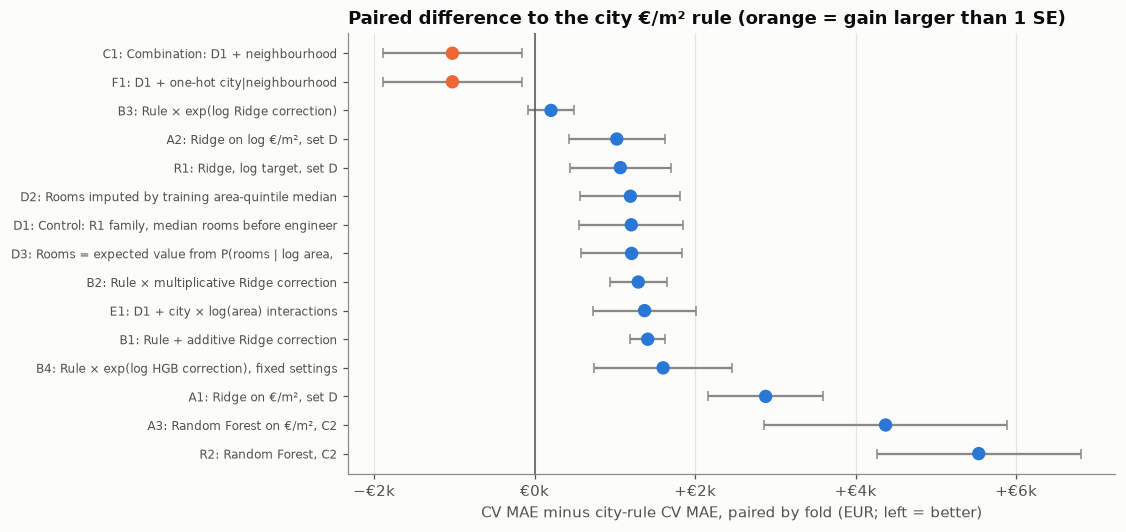

In [15]:
d = res.set_index('id').loc[[i for i in res['id'] if i != 'R0']].sort_values('paired_diff_vs_R0_mean', ascending=False)
fig, ax = plt.subplots(figsize=(9, 5.2))
col = [vplot.ORANGE if s else vplot.BLUE for s in d['signal_vs_R0']]
ax.errorbar(d['paired_diff_vs_R0_mean'], np.arange(len(d)), xerr=d['paired_diff_vs_R0_se'], fmt='none', ecolor=vplot.INK_3, lw=1.5, capsize=3)
ax.scatter(d['paired_diff_vs_R0_mean'], np.arange(len(d)), c=col, s=60, zorder=3)
ax.axvline(0, color=vplot.INK_2, lw=1)
ax.set_yticks(np.arange(len(d)), [f"{i}: {n.split(' (')[0][:48]}" for i, n in zip(d.index, d['notes'])], fontsize=8)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: ('+' if v > 0 else ('−' if v < 0 else '')) + f'€{abs(v)/1000:.0f}k'))
ax.set_xlabel('CV MAE minus city-rule CV MAE, paired by fold (EUR; left = better)')
ax.set_title('Paired difference to the city €/m² rule (orange = gain larger than 1 SE)')
ax.grid(axis='y', visible=False)
vplot.save(fig, FIG, 'rx_02_paired_difference_vs_rule'); plt.show()

**What it means:**
- **Lowest CV MAE:** F1 (= C1), €49,502 ± 4,452.
- **The final project's selection rule** (best + 1 SE = €51,493; simplest method within it) **still chooses the city €/m² rule R0**. The near-equals are F1, C1 and B3.
- **Large errors:** the lowest pooled RMSE belongs to B2 and B1 (≈ €102.1–102.4k, R² 0.59). The rule is close behind (€103.3k, 0.58). The differences are about 1%, too small to call any method better at controlling large errors.
- **Trees vs the rule:** the Random Forest (R2) has a **higher** RMSE (€105.6k) and lower R² (0.56) than the rule in cross-validation. On the final project's test set, the trees had looked much better (R² 0.63–0.64 vs 0.47). **That observation does not replicate on the larger development data**, so it should be presented as a property of that one test sample, not as a general finding.
- **Complexity vs gain:** every learned model needs more machinery than the rule. The only gain larger than its uncertainty (F1, about €1k, or 2%) comes from **better location data**, not from a more complex algorithm.

## 11. Out-of-fold error analysis

**What this code does:** Compares the out-of-fold errors of the city rule (R0), the reference ML model (R1), the best hybrid and the configuration with the lowest CV MAE, by price band, size band, city, location method and whether rooms are known. It shows n for every group, plus the mean error (bias: negative = underestimate).

**Why we need it:** The averages hide where each method fails. This shows whether a method reduces the rule's main weakness, the underestimation of expensive and large flats.

In [16]:
best_cv = res.sort_values('cv_mae_mean').iloc[0]['id']
COMP = list(dict.fromkeys(['R0', 'R1', best_b, best_cv, 'R2']))
e = dev[['record_id', 'price_eur', 'area_m2', 'city_clean', 'city_method', 'platform']].copy()
e['price_band'] = pd.cut(e['price_eur'], [0, 100_000, 200_000, 300_000, 500_000, np.inf], labels=['<100k', '100–200k', '200–300k', '300–500k', '≥500k'])
e['size_band'] = pd.cut(e['area_m2'], [0, 40, 60, 80, 120, np.inf], labels=['<40', '40–60', '60–80', '80–120', '≥120'])
e['location'] = e['city_method'].map(lambda m: 'unknown' if m in ('Ambiguous', 'Conflict', 'Unknown') else m)
e['rooms'] = np.where(miss, 'missing', 'known')
tabs = {}
for g in ['price_band', 'size_band', 'location', 'rooms', 'city_clean']:
    t = pd.DataFrame({'n': e.groupby(g, observed=True).size()})
    for m in COMP:
        err = OOF[m] - y
        t[f'MAE {m}'] = pd.Series(np.abs(err)).groupby(e[g].to_numpy()).mean()
        t[f'bias {m}'] = pd.Series(err).groupby(e[g].to_numpy()).mean()
    if g == 'city_clean':
        t = t[t['n'] >= 20]
    tabs[g] = t.round(0); print('---', g); display(tabs[g]); tabs[g].to_csv(RES / f'oof_errors_by_{g}.csv')
big = pd.DataFrame({m: {'errors > €200k (n)': int(np.sum(np.abs(OOF[m] - y) > 200_000)), '95th pct abs error': np.percentile(np.abs(OOF[m] - y), 95),
                        'pooled RMSE': np.sqrt(np.mean((OOF[m] - y) ** 2)), 'median abs error': np.median(np.abs(OOF[m] - y))} for m in COMP}).round(0)
display(big); big.to_csv(RES / 'large_error_summary.csv')

--- price_band


,n,MAE R0,bias R0,MAE R1,bias R1,MAE B3,bias B3,MAE C1,bias C1,MAE R2,bias R2
price_band,,,,,,,,,,,
<100k,92,19761.0,12597.0,22448.0,18981.0,21404.0,15591.0,22736.0,19092.0,26748.0,25672.0
100–200k,561,25818.0,11634.0,25715.0,14153.0,26366.0,14854.0,24777.0,12809.0,33060.0,19428.0
200–300k,270,51057.0,-11179.0,50855.0,-10993.0,49473.0,-9752.0,46529.0,-8058.0,56805.0,-750.0
300–500k,129,86350.0,-35449.0,90313.0,-36057.0,85511.0,-36296.0,85193.0,-29874.0,95411.0,-23839.0
≥500k,46,309418.0,-296179.0,320740.0,-306480.0,315892.0,-307700.0,321580.0,-308022.0,280104.0,-217061.0


--- size_band


,n,MAE R0,bias R0,MAE R1,bias R1,MAE B3,bias B3,MAE C1,bias C1,MAE R2,bias R2
size_band,,,,,,,,,,,
<40,149,20236.0,-10954.0,19417.0,-3410.0,19238.0,-7385.0,19126.0,-3625.0,22531.0,-623.0
40–60,394,29452.0,-8254.0,29797.0,-3787.0,29778.0,-3729.0,29664.0,-3565.0,33331.0,496.0
60–80,296,45241.0,-7386.0,45498.0,-8428.0,45404.0,-5813.0,41470.0,-7097.0,47526.0,-2849.0
80–120,196,80110.0,-17259.0,79349.0,-21442.0,79266.0,-18559.0,73602.0,-19011.0,87789.0,158.0
≥120,63,186467.0,-48840.0,205928.0,-52920.0,192142.0,-59905.0,207910.0,-55312.0,218640.0,11237.0


--- location


,n,MAE R0,bias R0,MAE R1,bias R1,MAE B3,bias B3,MAE C1,bias C1,MAE R2,bias R2
location,,,,,,,,,,,
Explicit location match,298,58978.0,-13623.0,59451.0,-14205.0,58914.0,-12281.0,61571.0,-14472.0,68113.0,-3117.0
Original valid city,571,34864.0,-4043.0,34795.0,-3889.0,34772.0,-2427.0,30455.0,-2792.0,38460.0,4945.0
Reviewed settlement mapping,202,65391.0,-21211.0,69942.0,-16976.0,66790.0,-19195.0,67712.0,-15677.0,71593.0,-7179.0
unknown,27,176583.0,-106563.0,181986.0,-79585.0,176929.0,-102934.0,182266.0,-80830.0,178425.0,-16523.0


--- rooms


,n,MAE R0,bias R0,MAE R1,bias R1,MAE B3,bias B3,MAE C1,bias C1,MAE R2,bias R2
rooms,,,,,,,,,,,
known,935,52612.0,-15209.0,54314.0,-11826.0,53115.0,-12560.0,52021.0,-11516.0,57627.0,-1723.0
missing,163,38451.0,4239.0,35844.0,-5977.0,36919.0,257.0,34951.0,-2999.0,46973.0,9873.0


--- city_clean


,n,MAE R0,bias R0,MAE R1,bias R1,MAE B3,bias B3,MAE C1,bias C1,MAE R2,bias R2
city_clean,,,,,,,,,,,
Bar,62,36161.0,6151.0,33013.0,-1392.0,34281.0,4358.0,35430.0,-4.0,44258.0,7493.0
Budva,184,64732.0,-18471.0,65738.0,-18237.0,65270.0,-15820.0,66559.0,-19566.0,78655.0,-2084.0
Cetinje,27,16525.0,1874.0,14229.0,1223.0,16430.0,3664.0,14709.0,1388.0,22464.0,13463.0
Herceg Novi,180,69214.0,-22279.0,74564.0,-16696.0,70719.0,-20434.0,73175.0,-14604.0,75935.0,-5476.0
Kolašin,41,43237.0,-19109.0,43741.0,-17006.0,43673.0,-19725.0,42905.0,-16367.0,42484.0,-6908.0
Kotor,46,62336.0,-3520.0,62516.0,-13240.0,62438.0,-3158.0,64288.0,-14548.0,69109.0,-19249.0
Nikšić,24,19101.0,-1936.0,18344.0,1855.0,18815.0,-144.0,18080.0,1533.0,33559.0,29167.0
Podgorica,389,30992.0,-2264.0,30709.0,-3761.0,30923.0,-971.0,24246.0,-1853.0,32349.0,3364.0
Tivat,62,82339.0,-31348.0,86743.0,-11527.0,81733.0,-26077.0,88332.0,-13260.0,81554.0,-11935.0


,R0,R1,B3,C1,R2
errors > €200k (n),41.0,47.0,42.0,46.0,50.0
95th pct abs error,156585.0,169228.0,163694.0,159621.0,182410.0
pooled RMSE,103310.0,105298.0,103703.0,104883.0,105601.0
median abs error,27025.0,27317.0,27509.0,23793.0,31016.0


**What this code does:** Draws the mean signed error (bias) by price band for the compared methods.

**Why we need it:** The rule's main weakness is underestimating expensive flats. This shows directly whether a method reduces it.

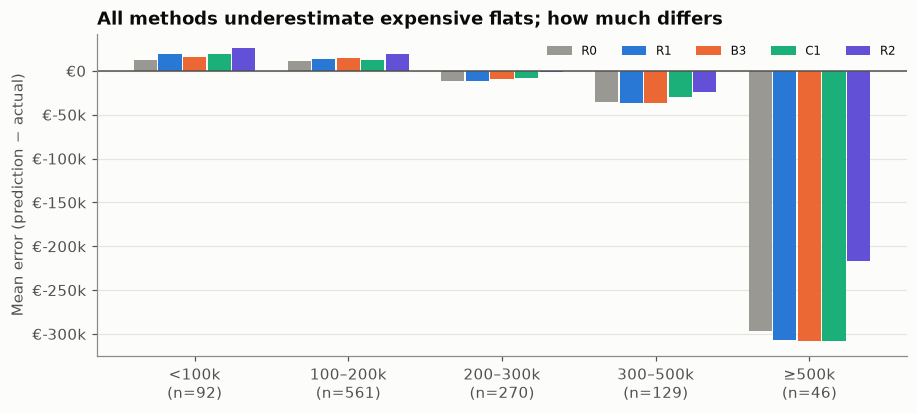

In [17]:
t = tabs['price_band']
fig, ax = plt.subplots(figsize=(9.5, 3.8)); x = np.arange(len(t)); cols = [vplot.GRAY, vplot.BLUE, vplot.ORANGE, vplot.AQUA, '#6250d6']
for j, m in enumerate(COMP):
    ax.bar(x + (j - (len(COMP) - 1) / 2) * 0.16, t[f'bias {m}'], width=0.15, color=cols[j], label=m)
ax.axhline(0, color=vplot.INK_2, lw=1)
ax.set_xticks(x, [f'{i}\n(n={n})' for i, n in zip(t.index.astype(str), t['n'])])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(vplot.euro)); ax.set_ylabel('Mean error (prediction − actual)')
ax.set_title('All methods underestimate expensive flats; how much differs'); ax.legend(ncols=len(COMP), fontsize=8); ax.grid(axis='x', visible=False)
vplot.save(fig, FIG, 'rx_03_bias_by_price_band'); plt.show()

**What it means** (out-of-fold, 1,098 development listings; n in every table):
- **All methods underestimate expensive flats.**
  - For flats ≥ €500k (n = 46) the mean error is −€296k (rule), −€308k (B3, best hybrid), −€308k (F1) and −€217k (Random Forest).
  - The forest is the least biased there, but it is worse for cheaper flats (it overestimates flats < €100k by +€26k) and worse overall.
- **None of the new approaches removes this weakness.** It needs information the data do not contain (quality, view, exact address).
- **Size:** for flats ≥ 120 m² (n = 63) the rule has the lowest MAE (€186k vs €192–219k).
- **Location:** listings with an unknown city (n = 27) have by far the largest errors for every method (≈ €177–182k).
  - Listings located by the platform city field (mostly Podgorica, n = 571) are where F1 helps (€34.9k → €30.5k).
  - Settlement-mapped coastal listings (n = 202) stay hard (≈ €65–72k).
- **Rooms:** listings without a room count are *easier* to predict (≈ €35–38k, n = 163), because they are smaller and cheaper flats. The rule overestimates them slightly (+€4k on average). R1 and F1 have a lower MAE there (≈ €35–36k vs €38.5k).
- **Errors above €200k:** 41 (rule), 42 (B3), 46 (F1), 50 (Random Forest).

## 12. Answers and recommendation

| # | Question | Answer (exploratory, development CV only) |
|---|---|---|
| 1 | Is predicting €/m² better than predicting total price? | **No.** Log €/m² ≈ log price (the same model). Plain €/m² is worse. It helps the Random Forest a little (−€1.2k, SE €0.9k), but the forest stays behind the rule. |
| 2 | Does the hybrid beat the simple rule? | **No.** B3 ties (+€204 ± 287); B1, B2 and B4 are worse on MAE. Nested tuning chose the strongest shrinkage. |
| 3 | Does estimating missing rooms help? | **No.** Rooms can be estimated from area (≈ 0.3 rooms error), but it adds nothing to the price model (±€11). |
| 4 | Does the area–rooms relationship add value? | **No evidence.** Area per room is part of the engineered set, which did not help in the final project, and rooms add little beyond area. |
| 5 | Do city-specific area effects help? | **No** (+€166 ± 349). The slopes are interesting descriptively, but they do not improve predictions. |
| 6 | Does finer location help? | **Yes, weakly and locally.** −€1,025 vs the rule (SE €864), −€2,229 vs its control (SE €441), almost all in Podgorica (−21%). It depends on one platform's capped sample, so it is exploratory. |
| 7 | Which features really contribute? | **Area** (by far), then the **city**, then the **neighbourhood within Podgorica**. Rooms, area interactions and €/m² targets add nothing measurable. |
| 8 | Which method controls large errors best? | **None clearly.** B1/B2 have about 1% lower RMSE than the rule. All methods underestimate flats ≥ €500k by €200–300k. The test-set impression that trees control large errors **did not replicate** in CV. |
| 9 | Best average CV MAE? | **F1** (€49,502 ± 4,452). The rule follows (€50,527 ± 6,297), then B3 (€50,731). |
| 10 | Is the extra complexity justified? | **Not for the final model.** The gains are within about one standard error, and the only real signal comes from better location data. |
| 11 | Which research question fits the findings? | *"Can machine learning improve apartment asking-price estimation in Montenegro compared with a simple city price-per-m² rule, and how much does location data quality contribute?"* The answer: **not with the available property features; location quality (city, and neighbourhood where it is well covered) is what matters.** It must be stated that the question was refined after the first results. |
| 12 | Recommendation for the Capstone | **Keep the completed, validated Capstone and its chosen model (the city €/m² rule).** Optionally add a short, clearly labelled exploratory appendix: hybrid, €/m², rooms and interactions give no gain; finer location helps in Podgorica (needs confirmation on new adverts). **Also correct the statement that trees control large errors better**: it is based on the test sample only and does not replicate in CV. |

**Possible next step (not run, would need its own pre-registration):** a *neighbourhood €/m² rule*, i.e. the training median €/m² of the neighbourhood if it has ≥ 10 listings, otherwise of the city. It would combine F1's location signal with the transparency of the current rule, and it should be tested on **newly collected** adverts.